## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set(style="whitegrid")

## Load Dataset

In [2]:
df = pd.read_csv("Health Insurance Dataset.csv")

In [3]:
df.head(3)

,age,sex,bmi,height,children,smoker,region,charges,Level,score
0,19,female,27.90,64.03,0,yes,southwest,16884.92,B,72
1,31,female,25.74,66.63,0,no,southeast,3756.62,B,71
2,46,female,33.44,61.39,1,no,southeast,8240.59,B,88


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   height    1338 non-null   float64
 4   children  1338 non-null   int64  
 5   smoker    1338 non-null   object 
 6   region    1338 non-null   object 
 7   charges   1338 non-null   float64
 8   Level     1338 non-null   object 
 9   score     1338 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 104.7+ KB


In [5]:
df.isnull().sum()

age         0
sex         0
bmi         0
height      0
children    0
smoker      0
region      0
charges     0
Level       0
score       0
dtype: int64

## Data Wrangling

In [6]:
# categorical data: text data/text columns

In [7]:
categorical_cols = ['sex', 'smoker', 'region', 'Level']

for col in categorical_cols:
    df[col] = df[col].astype('category')

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.describe()

,age,bmi,height,children,charges,score
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663987,66.607682,1.094918,13270.422292,65.967115
std,14.049960,6.098063,3.867210,1.205493,12110.011242,15.235684
min,18.000000,15.960000,54.280000,0.000000,1121.873900,0.000000
25%,27.000000,26.296250,63.816668,0.000000,4740.288500,56.250000
50%,39.000000,30.400000,66.601959,1.000000,9382.033000,66.000000
75%,51.000000,34.693750,69.465980,2.000000,16639.914427,77.000000
max,64.000000,53.130000,79.578403,5.000000,63770.430000,100.000000


# PART I: Univariate and Bivariate Analysis

## A1: Selected Variables

In [10]:
numeric_cols = ['age', 'charges']
categorical_cols = ['smoker', 'region']

## A2: Univariate Visualizations

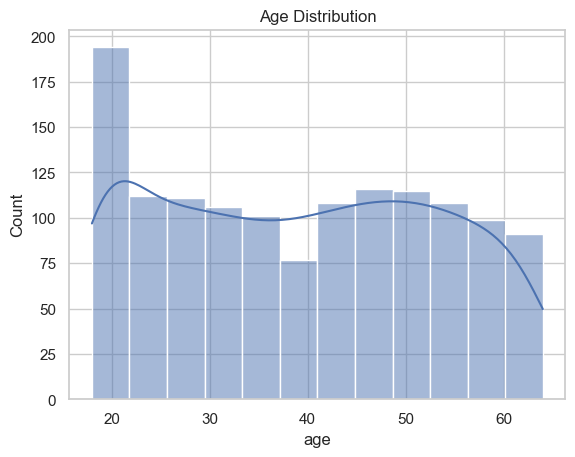

In [11]:
plt.figure()
sns.histplot(df['age'], kde=True)
plt.title("Age Distribution")
plt.show()

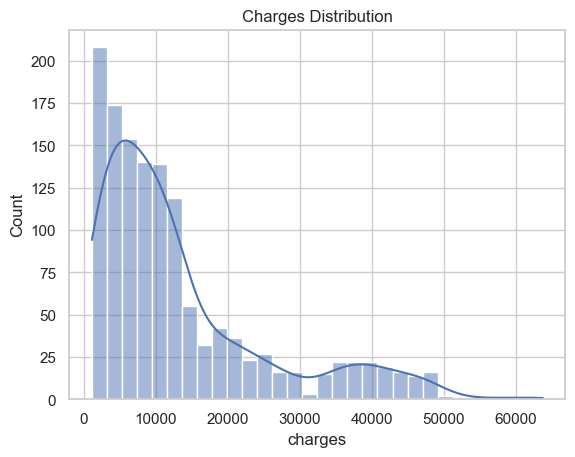

In [12]:
plt.figure()
sns.histplot(df['charges'], kde=True)
plt.title("Charges Distribution")
plt.show()

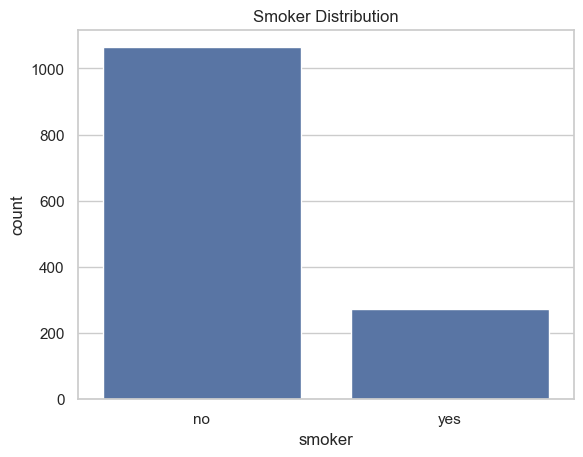

In [13]:
plt.figure()
sns.countplot(x='smoker', data=df)
plt.title("Smoker Distribution")
plt.show()

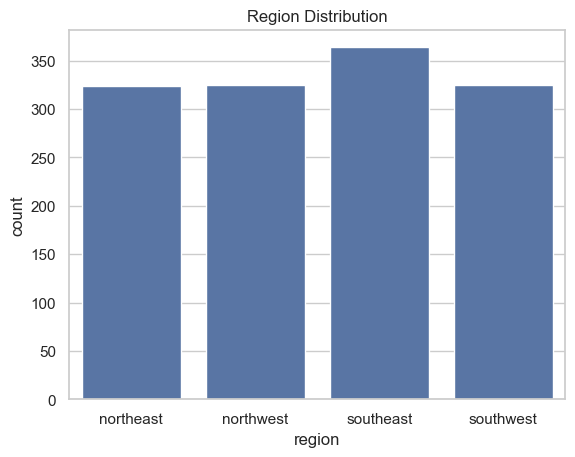

In [14]:
plt.figure()
sns.countplot(x='region', data=df)
plt.title("Region Distribution")
plt.show()

## A3: Bivariate Visualizations

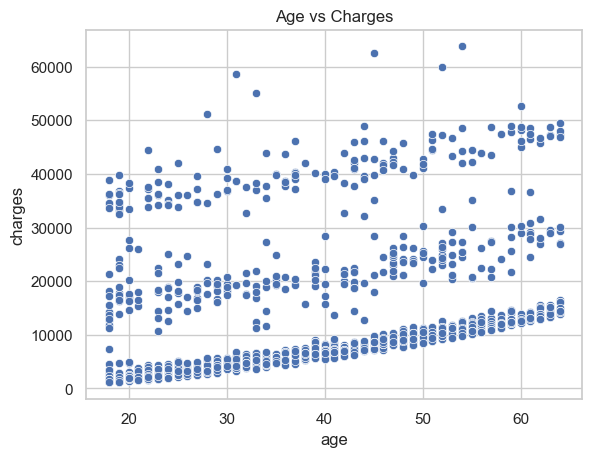

In [15]:
plt.figure()
sns.scatterplot(x='age', y='charges', data=df)
plt.title("Age vs Charges")
plt.show()

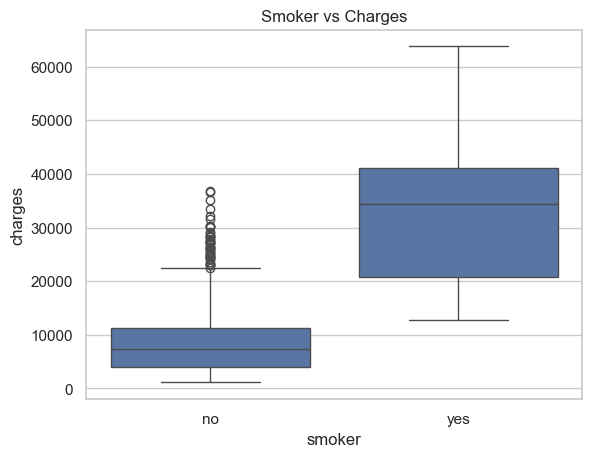

In [16]:
plt.figure()
sns.boxplot(x='smoker', y='charges', data=df)
plt.title("Smoker vs Charges")
plt.show()

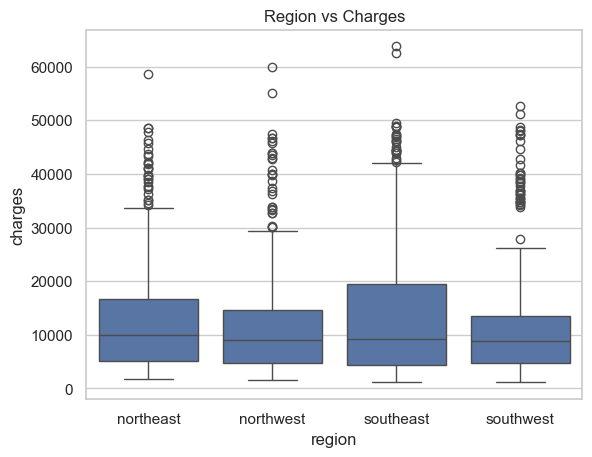

In [17]:
plt.figure()
sns.boxplot(x='region', y='charges', data=df)
plt.title("Region vs Charges")
plt.show()

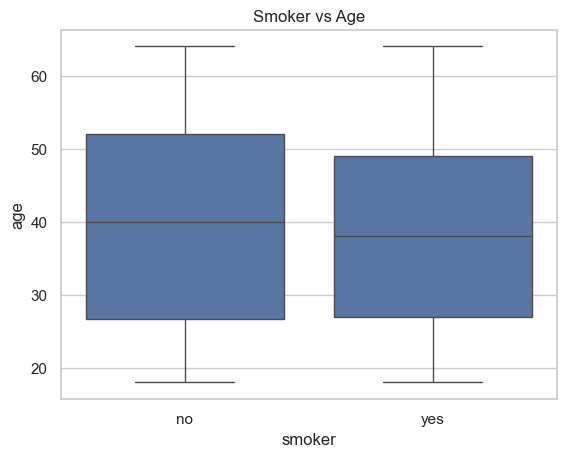

In [18]:
plt.figure()
sns.boxplot(x='smoker', y='age', data=df)
plt.title("Smoker vs Age")
plt.show()

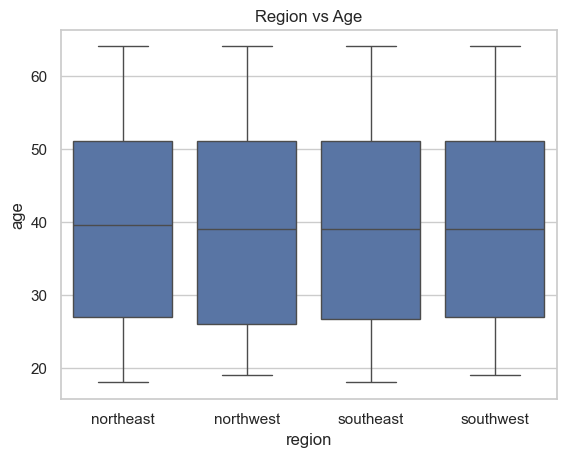

In [29]:
plt.figure()
sns.boxplot(x='region', y='age', data=df)
plt.title("Region vs Age")
plt.show()

## Correlation Analysis

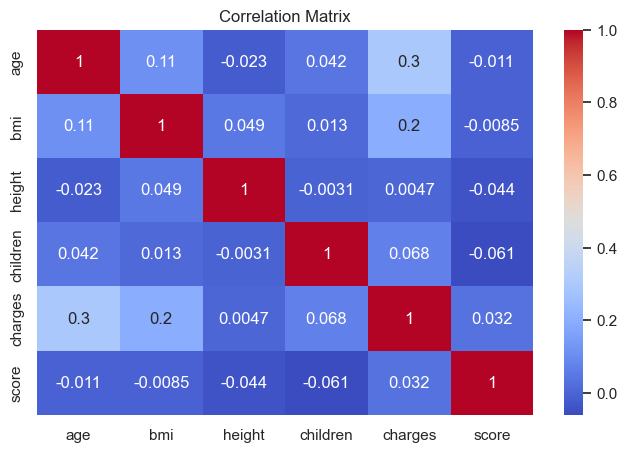

In [20]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

## B1: Descriptive Statistics – Numerical Variables

In [21]:
df[['age', 'bmi', 'charges', 'score']].describe()

,age,bmi,charges,score
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663987,13270.422292,65.967115
std,14.049960,6.098063,12110.011242,15.235684
min,18.000000,15.960000,1121.873900,0.000000
25%,27.000000,26.296250,4740.288500,56.250000
50%,39.000000,30.400000,9382.033000,66.000000
75%,51.000000,34.693750,16639.914427,77.000000
max,64.000000,53.130000,63770.430000,100.000000


In [22]:
df[['age', 'bmi', 'charges', 'score']].agg(['mean', 'median', 'std', 'var', 'min', 'max'])

,age,bmi,charges,score
mean,39.207025,30.663987,1.327042e+04,65.967115
median,39.000000,30.400000,9.382033e+03,66.000000
std,14.049960,6.098063,1.211001e+04,15.235684
var,197.401387,37.186374,1.466524e+08,232.126068
min,18.000000,15.960000,1.121874e+03,0.000000
max,64.000000,53.130000,6.377043e+04,100.000000


In [23]:
# range
df[['age', 'bmi', 'charges', 'score']].quantile([0.25, 0.5, 0.75])

range_values = df[['age', 'bmi', 'charges', 'score']].max() - df[['age', 'bmi', 'charges', 'score']].min()

print(range_values)

age           46.0000
bmi           37.1700
charges    62648.5561
score        100.0000
dtype: float64


## B2: Descriptive Statistics – Categorical Variables

In [24]:
for col in ['sex', 'smoker', 'region', 'Level']:
    print(col)
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100) # important 

# here we are normalizing that values between 0 to 1 range.
# Normalization: it converts that values in 0-1 range.

sex
sex
male      676
female    662
Name: count, dtype: int64
sex
male      50.523169
female    49.476831
Name: proportion, dtype: float64
smoker
smoker
no     1064
yes     274
Name: count, dtype: int64
smoker
no     79.521674
yes    20.478326
Name: proportion, dtype: float64
region
region
southeast    364
northwest    325
southwest    325
northeast    324
Name: count, dtype: int64
region
southeast    27.204783
northwest    24.289985
southwest    24.289985
northeast    24.215247
Name: proportion, dtype: float64
Level
Level
C    427
D    348
B    264
E    187
A    112
Name: count, dtype: int64
Level
C    31.913303
D    26.008969
B    19.730942
E    13.976084
A     8.370703
Name: proportion, dtype: float64


# PART II: Parametric Statistical Testing

## C1: Research Question

Do smokers have significantly higher insurance charges than non-smokers?

## D1: Statistical Test Selection

"Independent Sample T-Test"

## D2: Relevant Variables

In [25]:
variables = ['smoker', 'charges']
variables

['smoker', 'charges']

## D3: Justification

"T-test is used because charges is numerical and smoker is a binary categorical variable."

## D4: Hypotheses

"H0: Mean charges of smokers = Mean charges of non-smokers"

"H1: Mean charges of smokers ≠ Mean charges of non-smokers"

## D5: Test Execution

In [30]:
smoker = df[df['smoker'].str.lower() == 'yes']['charges']
non_smoker = df[df['smoker'].str.lower() == 'no']['charges']

t_stat, p_value = stats.ttest_ind(smoker, non_smoker, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 32.75188719942078
P-value: 5.889493414643693e-103


# PART III: Non-Parametric Statistical Testing

## G1: Research Question

"Is there a significant difference in charges across regions?"

## H1: Statistical Test Selection

"Kruskal-Wallis Test"

## H2: Relevant Variables

In [27]:
variables = ['region', 'charges']
variables

['region', 'charges']

## H3: Justification

"Kruskal-Wallis is used because charges is numerical and region has more than two categories."

## H4: Hypotheses

"H0: All regions have equal distribution of charges"

"H1: At least one region differs"

## H5: Test Execution

In [28]:
regions = df['region'].unique()

groups = [df[df['region'] == region]['charges'] for region in regions]

stat, p_value = stats.kruskal(*groups)
# 0.192 > 0.05
stat, p_value

(4.734181215658743, 0.19232908072121002)